In [2]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch
from matplotlib.patches import PathPatch
from matplotlib.path import Path

In [4]:
df = pd.read_csv('AbsTimes_CNORecall.csv')
#df = pd.read_csv('test.csv')

print(df)

    Group         CS-         CS+ Control
0       1  155.879100  144.120900       y
1       2  150.192184  149.807816       y
2       3  270.870000   29.130000       n
3       4  180.140000  119.860000       y
4       5  228.465000   71.535000       y
5       6  130.650000  169.350000       y
6       7  215.240000   84.760000       n
7       8  157.560000  142.440000       y
8       9  154.900000  145.100000       y
9      10  168.000000  132.000000       y
10     11  169.065000  130.935000       y
11     12  127.350000  172.650000       y
12     13  137.170000  162.830000       y
13     14  160.775800  139.224200       y
14     15  242.747093   57.252907       n
15     16  232.942196   67.057803       n
16     17  246.383413   53.616587       n
17     18  218.222790   81.777210       n
18     19  195.629100  104.370900       n
19     20  240.874900   59.125100       n
20     21  225.200000   74.800000       n
21     22  246.424709   53.575291       n
22     23  235.990000   64.010000 

In [5]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

def map_half(i,num):
    if(i < num/2):
        return 0
    return 1

In [6]:
def marker(filled=False):
    if (filled):
        return 'o'
    pts = np.linspace(0, np.pi * 2, 24)
    circ = np.c_[np.sin(pts) / 2, -np.cos(pts) / 2]
    vert = np.r_[circ, circ[::-1] * .7]
    return Path(vert)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


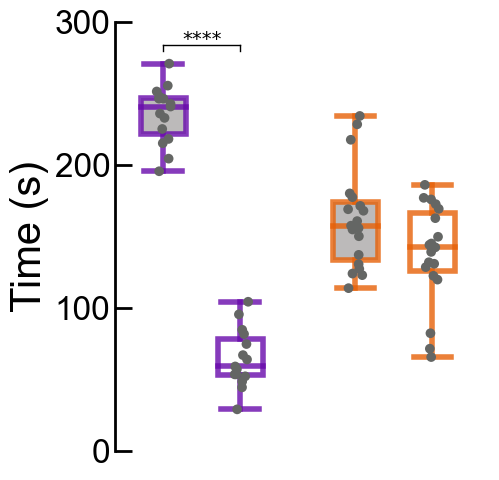

In [9]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['','****']
colors = ["#646664","#646664"]
colors_boxplot = [ "#680aab", '#e66007']
colors_boxplot_filling = ['#03f',"#c14"]
colors_boxplot_filling = ['#aba9a9',"#aba9a9"]


ax = sns.stripplot(
    data=newdf,
    hue='Experimental Condition',
    order = ['n','y'],
    y='Left preference',
    x='control',
    marker=marker(True),
    palette=colors,
    size=7,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    hue='Experimental Condition',
    order = ['n','y'],
    y='Left preference',
    x='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)

#plt.axhline(linewidth=2, color='lightgrey',ls='--')

data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches


for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[map_half(i,len(box_patches))]
    col_fill = colors_boxplot_filling[map_half(i,len(box_patches))]
    facecolor = col_fill if i%2==0 else 'None'
    patch.set_edgecolor(col)
    patch.set_facecolor(facecolor)
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

        

#handles, labels = ax.get_legend_handles_labels()
#l = plt.legend(handles[0:2], ["", ""],loc=2)

plt.legend([],[], frameon=False)

ax.set_xticklabels(['Cups','Social'], fontsize = 26)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.spines['left'].set_color('black')


ax.set_xlabel("",fontsize=20)

###


ax.set_yticks(np.arange(0,301,100), fontname='Arial')
ax.set_yticklabels(['0','100','200','300'],fontname='Arial')


ax.set_xticks('')

ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)

plt.legend([],[], frameon=False)


ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Time (s)', fontsize = 30, fontname='Arial')


ax.set_ylim([0,300])
ax.set_xlim([-0.45,1.5])


significance(ax,0,data_ratio,newdf.loc[newdf['control']=='n']['Left preference'].max()+17,text=text_boxplot[1],offset=-4,whisker=4)


fig = ax.get_figure()
adjust_box_widths(fig, 0.6)
fig.set_size_inches(5.1,4.9)
ax.tick_params(axis='y', which='major', labelsize=24)
ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)


plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig3a_AbsTimesCNORecall.jpg",dpi=600,bbox_inches='tight')
plt.savefig('Fig3a_AbsTimesCNORecall.eps', format='eps', dpi=600)

